# Temporal graph modeling

**Analytical question:** Represent changing player interactions.

**Stages in this notebook:** Lagged features; identity edges; graph embeddings; recurrent, convolutional and masked-attention alternatives.

This is one complete analytical workflow. Its helper functions and intermediate steps are sections within the notebook, rather than separate notebooks. All required code is inline: downloading, kloppy loading, reshaping, plotting and method calculations. No local `.py` helper or prior notebook session is required. Set `DATA_ROOT` below to reuse another cache; absent data are downloaded from the pinned SkillCorner open-data revision.

Run top to bottom and inspect each intermediate table and visual before interpreting the final result. Some calculations are explicitly teaching baselines or synthetic training checks, not exact research/provider implementations or measured soccer-model performance. Dependencies are listed in the repository requirements and the imports below.


## 1. Imports and data location

In [1]:
from pathlib import Path
import json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from IPython.display import display
from kloppy import skillcorner

# Change DATA_ROOT to use an existing cache elsewhere. No local Python modules are imported.
candidates=[Path.cwd(),*Path.cwd().parents]
ROOT=next((p for p in candidates if (p/'data/1925299/1925299_match.json').exists()),Path.cwd())
DATA_ROOT=ROOT/'data/1925299'


## 2. Inline ingestion and plotting helpers

In [2]:
def ensure_sample(destination):
    """Download only missing data files. Tracking is bounded to 9000 source records."""
    destination.mkdir(parents=True,exist_ok=True)
    revision='4340d274572876239c154c90bc507a9b3250a656'
    base=f'https://raw.githubusercontent.com/SkillCorner/opendata/{revision}/data/matches/1925299/'
    for suffix in ['match.json','dynamic_events.csv','phases_of_play.csv']:
        name='1925299_'+suffix;target=destination/name
        if not target.exists():
            with urllib.request.urlopen(base+name,timeout=90) as response:target.write_bytes(response.read())
    name='1925299_tracking_extrapolated.jsonl';target=destination/name
    if not target.exists():
        url=base.replace('raw.githubusercontent.com/','media.githubusercontent.com/media/')+name
        temporary=destination/(name+'.partial')
        with urllib.request.urlopen(url,timeout=90) as response,temporary.open('wb') as output:
            count=0
            for line in response:
                if line.strip():
                    json.loads(line);output.write(line);count+=1
                if count>=9000:break
        temporary.replace(target)

def read_tracking(destination):
    """Load kloppy coordinates and explicitly reshape player columns to rows."""
    dataset=skillcorner.load(meta_data=destination/'1925299_match.json',raw_data=destination/'1925299_tracking_extrapolated.jsonl',coordinates='skillcorner')
    wide=dataset.to_df()
    metadata=json.loads((destination/'1925299_match.json').read_text(encoding='utf-8'))
    raw=[json.loads(line) for line in (destination/'1925299_tracking_extrapolated.jsonl').read_text().splitlines() if line.strip()]
    player_possession={r['frame']:str(r.get('possession',{}).get('player_id')) for r in raw}
    visibility={(r['frame'],str(p['player_id'])):p.get('is_detected') for r in raw for p in r.get('player_data',[])}
    parts=[]
    for p in metadata['players']:
        pid=str(p['id'])
        if f'{pid}_x' not in wide:continue
        part=wide[['period_id','frame_id','timestamp','ball_owning_team_id',f'{pid}_x',f'{pid}_y']].copy()
        part.columns=['period_id','frame_id','timestamp','team_in_possession','x','y']
        part['player_id']=pid;part['team_id']=p['team_id'];part['name']=p['short_name'];parts.append(part)
    tracking=pd.concat(parts,ignore_index=True)
    tracking['seconds']=tracking.timestamp.dt.total_seconds()
    tracking['player_in_possession']=tracking.frame_id.map(player_possession)
    tracking['is_detected']=[visibility.get((f,p)) for f,p in zip(tracking.frame_id,tracking.player_id)]
    tracking=tracking.sort_values(['player_id','period_id','frame_id'])
    return dataset,wide,tracking,metadata,raw

def pitch(ax=None):
    """Draw a 105 by 68 metre pitch in native centered coordinates."""
    if ax is None:_,ax=plt.subplots(figsize=(9,5.5))
    ax.set_facecolor('#eef3ed')
    ax.add_patch(Rectangle((-52.5,-34),105,68,fill=False,color='#597063'))
    ax.plot([0,0],[-34,34],c='#597063');ax.add_patch(Circle((0,0),9.15,fill=False,color='#597063'))
    for x in [-52.5,36]:ax.add_patch(Rectangle((x,-20.16),16.5,40.32,fill=False,color='#597063'))
    ax.set(xlim=(-55,55),ylim=(-36,36),aspect='equal',xlabel='x (m)',ylabel='y (m)')
    return ax


## 3. Read the real sample

In [3]:
ensure_sample(DATA_ROOT)
dataset,wide,tracking,metadata,raw=read_tracking(DATA_ROOT)
events=pd.read_csv(DATA_ROOT/'1925299_dynamic_events.csv')
phases=pd.read_csv(DATA_ROOT/'1925299_phases_of_play.csv')
observed=tracking.dropna(subset=['x','y'])
complete=observed.groupby(['period_id','frame_id']).size()
frame_id=int(complete[complete.eq(22)].index[20][1])
snapshot=observed[observed.frame_id.eq(frame_id)].copy()
keepers={str(p['id']) for p in metadata['players'] if 'goalkeeper' in p['player_role']['name'].lower()}
role_labels={str(p['id']):p['player_role']['acronym'] for p in metadata['players']}
assert not tracking.duplicated(['period_id','frame_id','player_id']).any()
display(tracking[['period_id','frame_id','player_id','x','y','is_detected']].head(3))
print('Real bounded sample. Diagnostic frame:',frame_id)


,period_id,frame_id,player_id,x,y,is_detected
67683,1,40,11897,-22.46,-10.06,True
67684,1,41,11897,-22.46,-10.06,True
67685,1,42,11897,-22.47,-10.05,True


Real bounded sample. Diagnostic frame: 61


## Historical features and temporal identity edges
Build backward displacement and velocity without future frames. Same-player edges connect consecutive observations within a period. A one-second lag uses ten frames at this sample's native ten Hz, with an elapsed-time check. Never bridge substitutions, missing identity observations or period boundaries.

In [4]:
history=tracking.sort_values(['player_id','period_id','frame_id']).copy()
groups=history.groupby(['player_id','period_id'])
history['lag_frame']=groups.frame_id.shift(10)
history['lag_time']=groups.seconds.shift(10)
valid=history.frame_id.sub(history.lag_frame).eq(10)&np.isclose(history.seconds-history.lag_time,1)
history['dx_1s']=(history.x-groups.x.shift(10)).where(valid)
history['dy_1s']=(history.y-groups.y.shift(10)).where(valid)
temporal=[]
for (pid,period),g in observed.groupby(['player_id','period_id']):
    g=g.sort_values('frame_id')
    for a,b in zip(g.itertuples(),list(g.itertuples())[1:]):
        if b.frame_id-a.frame_id==1 and 0<b.seconds-a.seconds<.2:
            temporal.append((pid,period,a.frame_id,b.frame_id,b.seconds-a.seconds))
temporal=pd.DataFrame(temporal,columns=['player_id','period','source_frame','target_frame','dt'])
assert temporal.target_frame.gt(temporal.source_frame).all()
display(history[['player_id','frame_id','dx_1s','dy_1s']].dropna().head())
display(temporal.head())

,player_id,frame_id,dx_1s,dy_1s
67693,11897,50,-0.20,0.15
67694,11897,51,-0.24,0.20
67695,11897,52,-0.27,0.24
67696,11897,53,-0.31,0.30
67697,11897,54,-0.36,0.35


,player_id,period,source_frame,target_frame,dt
0,11897,1,40,41,0.1
1,11897,1,41,42,0.1
2,11897,1,42,43,0.1
3,11897,1,43,44,0.1
4,11897,1,44,45,0.1


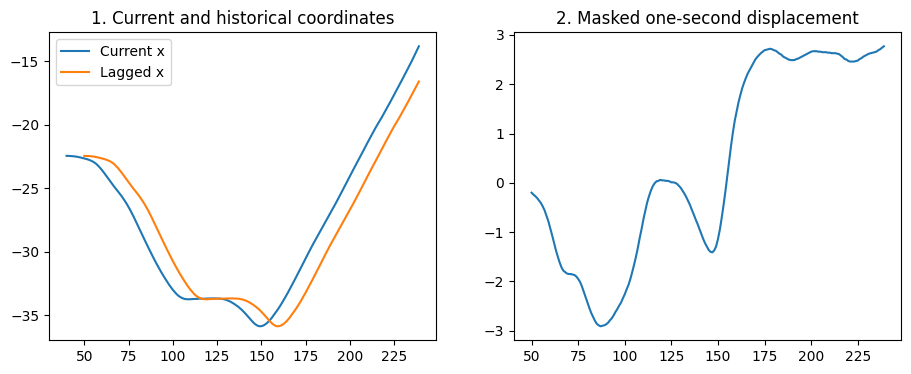

In [5]:
player=history[history.dx_1s.notna()].player_id.iloc[0]
g=history[history.player_id.eq(player)].head(200)
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].plot(g.frame_id,g.x,label='Current x')
axs[0].plot(g.frame_id,g.groupby('period_id').x.shift(10),label='Lagged x')
axs[0].legend()
axs[0].set_title('1. Current and historical coordinates')
axs[1].plot(g.frame_id,g.dx_1s)
axs[1].set_title('2. Masked one-second displacement')
plt.show()

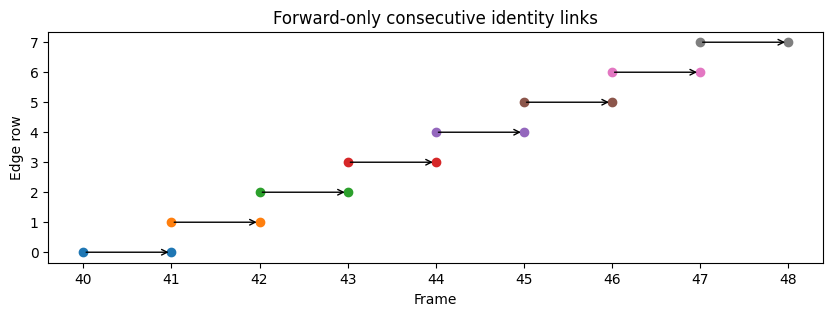

,player_id,period,source_frame,target_frame,dt
0,11897,1,40,41,0.1
1,11897,1,41,42,0.1
2,11897,1,42,43,0.1
3,11897,1,43,44,0.1
4,11897,1,44,45,0.1
5,11897,1,45,46,0.1
6,11897,1,46,47,0.1
7,11897,1,47,48,0.1


In [6]:
g=temporal.head(8)
fig,ax=plt.subplots(figsize=(10,3))
for i,r in enumerate(g.itertuples()):ax.annotate('',xy=(r.target_frame,i),xytext=(r.source_frame,i),arrowprops=dict(arrowstyle='->'));ax.scatter([r.source_frame,r.target_frame],[i,i])
ax.set(xlabel='Frame',ylabel='Edge row',title='Forward-only consecutive identity links')
plt.show()
display(g)

#### Helper: `make_graph`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [7]:
def make_graph(nodes,radius=15):
    nodes=nodes.sort_values('player_id');position=nodes[['x','y']].to_numpy()
    X=np.c_[position/np.array([52.5,34]),nodes.team_id.eq(1802).astype(float)]
    distance=np.linalg.norm(position[:,None]-position[None,:],axis=-1)
    A=(distance<=radius).astype(float) # includes self loops
    A=A/A.sum(axis=1,keepdims=True)
    return X,A,nodes.player_id.to_numpy()

,x_scaled,y_scaled,team
11897,-0.452571,-0.264118,0.0
287934,0.102667,0.147941,1.0
50982,-0.489714,0.685882,0.0
50999,0.694286,0.025294,1.0
51002,-0.084000,0.048529,1.0
51043,-0.139429,0.952647,1.0
51050,0.164762,0.020294,1.0
51694,-0.322857,0.350882,0.0
560882,-0.141524,0.285882,1.0
560983,0.141714,-0.196176,1.0


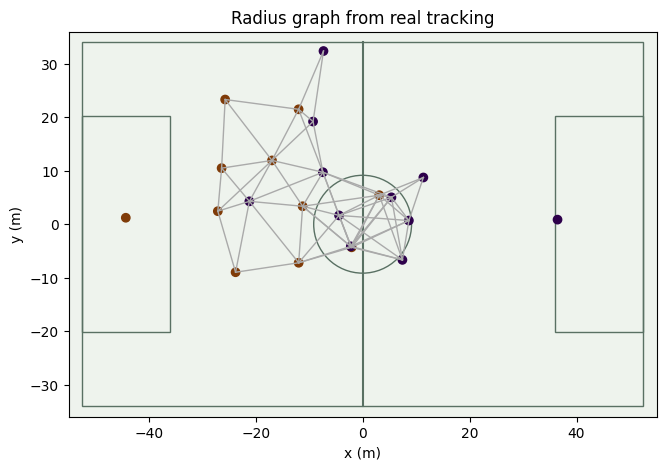

In [8]:
X,A,ids=make_graph(snapshot)
display(pd.DataFrame(X,index=ids,columns=['x_scaled','y_scaled','team']))
fig,ax=plt.subplots(figsize=(9,5))
pitch(ax)
pos=snapshot.set_index('player_id').loc[ids,['x','y']].to_numpy()
for i,j in zip(*np.where(np.triu(A>0,1))):ax.plot(pos[[i,j],0],pos[[i,j],1],c='#aaa',lw=1)
ax.scatter(pos[:,0],pos[:,1],c=X[:,2],cmap='PuOr')
ax.set_title('Radius graph from real tracking')
plt.show()

#### Helper: `adjacency_steps`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [9]:
def adjacency_steps(position,radius):
    distance=np.sqrt(((position[:,None]-position[None])**2).sum(axis=-1))
    binary=(distance<=radius).astype(float)
    normalized=binary/binary.sum(axis=1,keepdims=True)
    return distance,binary,normalized

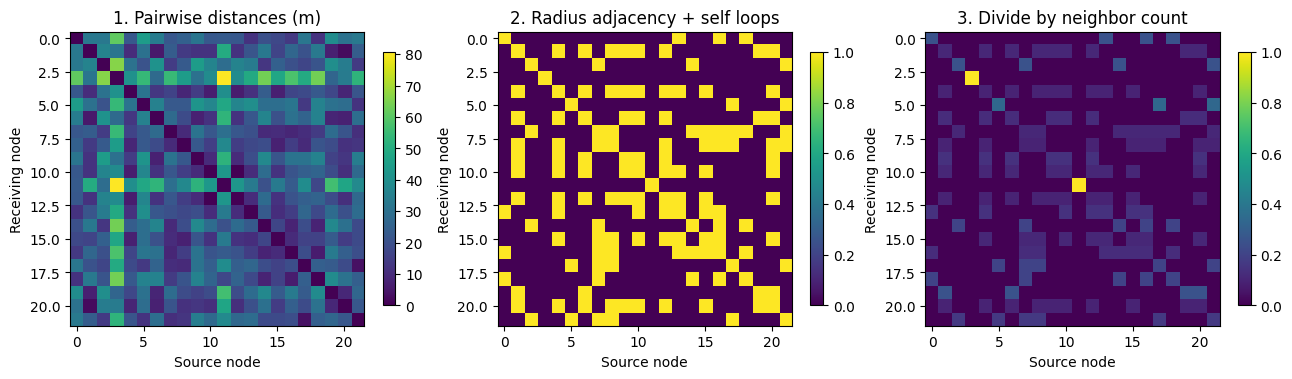

In [10]:
distance,binary,normalized=adjacency_steps(pos,15)
fig,axs=plt.subplots(1,3,figsize=(13,4))
for ax,data,title in zip(axs,[distance,binary,normalized],['1. Pairwise distances (m)','2. Radius adjacency + self loops','3. Divide by neighbor count']):
    image=ax.imshow(data,cmap='viridis');ax.set_title(title);ax.set(xlabel='Source node',ylabel='Receiving node');fig.colorbar(image,ax=ax,shrink=.7)
assert np.allclose(normalized.sum(axis=1),1)
plt.tight_layout()
plt.show()

#### Helper: `encode`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [11]:
def encode(X,A,W):return np.tanh(A@X@W)

#### Helper: `graph_probability`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [12]:
def graph_probability(X,A,W,head,bias=0):
    H=encode(X,A,W);g=H.mean(axis=0);return 1/(1+np.exp(-np.clip(g@head+bias,-40,40)))

In [13]:
rng=np.random.default_rng(4)
W=rng.normal(0,.1,(X.shape[1],8))
head=rng.normal(0,.1,8)
embedding=encode(X,A,W)
display(pd.DataFrame(embedding,index=ids).head())
permutation=rng.permutation(len(X))
assert np.isclose(graph_probability(X,A,W,head),graph_probability(X[permutation],A[np.ix_(permutation,permutation)],W,head))
print('Permutation-invariance check passed. Random weights are not EPV predictions.')

,0,1,2,3,4,5,6,7
11897,-0.010627,0.032837,-0.076271,-0.059278,0.046994,-0.020145,0.044804,-0.024377
287934,-0.158852,0.086023,-0.017431,-0.057358,-0.056208,-0.049558,0.019079,0.003939
50982,-0.054305,0.018689,-0.052488,0.052417,0.078800,0.025433,-0.049722,0.105237
50999,-0.236332,0.098342,0.082924,-0.038297,-0.176907,-0.066174,-0.009044,0.005011
51002,-0.114287,0.066750,-0.024203,-0.052994,-0.034438,-0.039754,0.022998,-0.004674


Permutation-invariance check passed. Random weights are not EPV predictions.


#### Helper: `message_steps`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [14]:
def message_steps(X,A,W):
    neighbor_average=A@X
    linear=neighbor_average@W
    hidden=np.tanh(linear)
    pooled=hidden.mean(axis=0)
    return neighbor_average,linear,hidden,pooled

,node_id,own_x,neighbor_average_x,linear_channel_0,hidden_channel_0
0,11897,-0.452571,-0.399905,-0.010628,-0.010627
1,287934,0.102667,0.041989,-0.160209,-0.158852
2,50982,-0.489714,-0.385714,-0.054358,-0.054305
3,50999,0.694286,0.694286,-0.240885,-0.236332
4,51002,-0.084000,-0.028000,-0.114788,-0.114287
5,51043,-0.139429,-0.181333,-0.231112,-0.227084
6,51050,0.164762,0.064929,-0.151695,-0.150542
7,51694,-0.322857,-0.332656,-0.098002,-0.097689
8,560882,-0.141524,-0.145029,-0.142356,-0.141402
9,560983,0.141714,0.043293,-0.138079,-0.137208


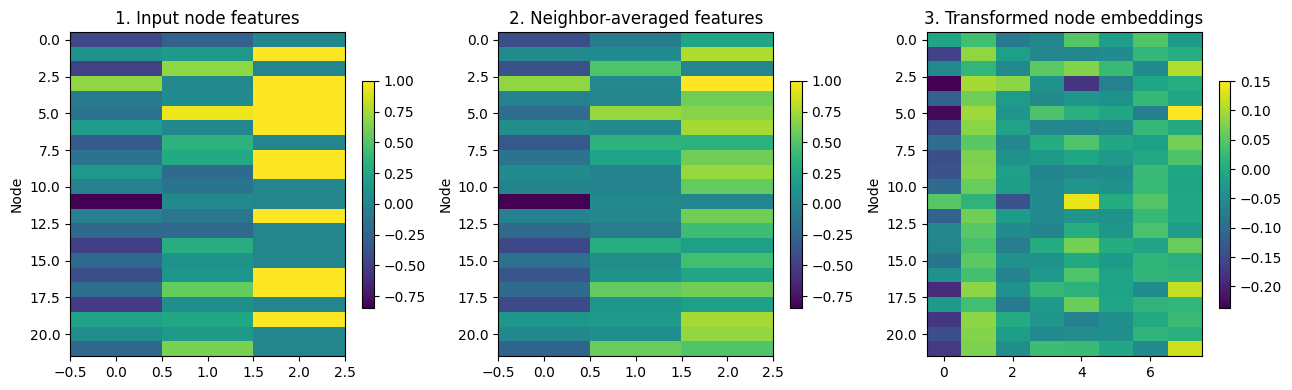

Pooling averages each embedding channel: [-0.1111  0.0614 -0.0382 -0.0273 -0.0017 -0.0246  0.0034  0.0301]


In [15]:
aggregate,linear,hidden,pooled=message_steps(X,A,W)
display(pd.DataFrame({'node_id':ids,'own_x':X[:,0],'neighbor_average_x':aggregate[:,0],'linear_channel_0':linear[:,0],'hidden_channel_0':hidden[:,0]}).head(10))
fig,axs=plt.subplots(1,3,figsize=(13,4))
for ax,data,title in zip(axs,[X,aggregate,hidden],['1. Input node features','2. Neighbor-averaged features','3. Transformed node embeddings']):
    im=ax.imshow(data,aspect='auto');ax.set_title(title);ax.set_ylabel('Node');fig.colorbar(im,ax=ax,shrink=.7)
plt.tight_layout()
plt.show()
print('Pooling averages each embedding channel:',pooled.round(4))

In [16]:
available=observed.groupby('frame_id').size()
available=set(available[available.eq(22)].index)
start=next(f for f in sorted(available) if all(f+j in available for j in range(10)))
Z=[]
for f in range(start,start+10):
    Xi,Ai,_=make_graph(observed[observed.frame_id.eq(f)]);Z.append(encode(Xi,Ai,W).mean(axis=0))
Z=np.array(Z)
d=Z.shape[1]
rng=np.random.default_rng(9)

#### Helper: `recurrent_states`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [17]:
def recurrent_states(Z,U,R):
    state=np.zeros(R.shape[0]);history=[]
    for z in Z:state=np.tanh(z@U+state@R);history.append(state.copy())
    return np.array(history)

,input_0,hidden_0
0,-0.110701,0.012791
1,-0.110689,0.016340
2,-0.110656,0.016208
3,-0.110638,0.016270
4,-0.109979,0.016232
5,-0.109777,0.016156
6,-0.110031,0.016162
7,-0.110171,0.016173
8,-0.110143,0.016141
9,-0.110111,0.016101


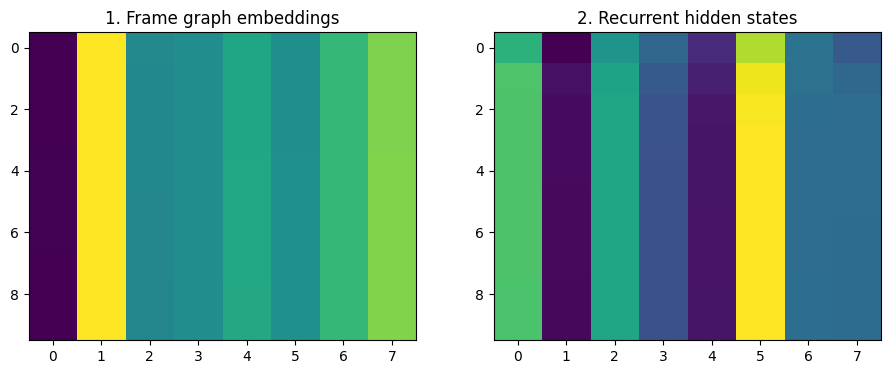

In [18]:
U=rng.normal(0,.1,(d,d))
R=rng.normal(0,.1,(d,d))
states=recurrent_states(Z,U,R)
display(pd.DataFrame({'input_0':Z[:,0],'hidden_0':states[:,0]}))
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].imshow(Z,aspect='auto')
axs[0].set_title('1. Frame graph embeddings')
axs[1].imshow(states,aspect='auto')
axs[1].set_title('2. Recurrent hidden states')
plt.show()

#### Helper: `causal_convolution`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [19]:
def causal_convolution(Z,kernel):
    result=[];contributions=[]
    for t in range(len(Z)):
        pieces=[kernel[k]*Z[t-k] for k in range(min(len(kernel),t+1))]
        contributions.append(pieces);result.append(np.sum(pieces,axis=0))
    return np.array(result),contributions

,0,1,2,3,4,5,6,7
current contribution,-0.066066,0.035925,-0.019479,-0.016083,-0.004578,-0.015036,0.001855,0.016499
lag 1 contribution,-0.033043,0.017946,-0.009634,-0.008029,-0.002404,-0.007529,0.000916,0.008214
lag 2 contribution,-0.011017,0.005977,-0.003180,-0.002673,-0.000836,-0.002513,0.000302,0.002727


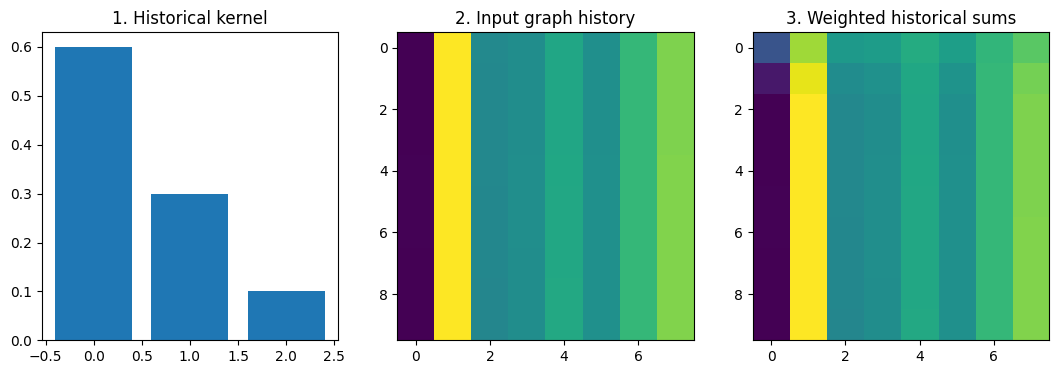

In [20]:
kernel=np.array([.6,.3,.1])
filtered,pieces=causal_convolution(Z,kernel)
display(pd.DataFrame(np.array(pieces[-1]),index=['current contribution','lag 1 contribution','lag 2 contribution']))
fig,axs=plt.subplots(1,3,figsize=(13,4))
axs[0].bar(range(3),kernel)
axs[0].set_title('1. Historical kernel')
axs[1].imshow(Z,aspect='auto')
axs[1].set_title('2. Input graph history')
axs[2].imshow(filtered,aspect='auto')
axs[2].set_title('3. Weighted historical sums')
plt.show()

### Intermediate steps: Inspect the attention mask before the weighted output

Future frames are excluded before normalization. These weights illustrate mechanics, not trained tactical importance.

Run the helper functions, inspect their returned arrays/tables, then compare the panels in calculation order.

#### Helper: `causal_attention_steps`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [21]:
def causal_attention_steps(Z):
    scores=Z@Z.T/np.sqrt(Z.shape[1])
    allowed=np.tril(np.ones_like(scores,dtype=bool))
    masked=np.where(allowed,scores,-np.inf)
    weights=np.exp(masked-masked.max(axis=1,keepdims=True));weights/=weights.sum(axis=1,keepdims=True)
    return scores,allowed,weights,weights@Z

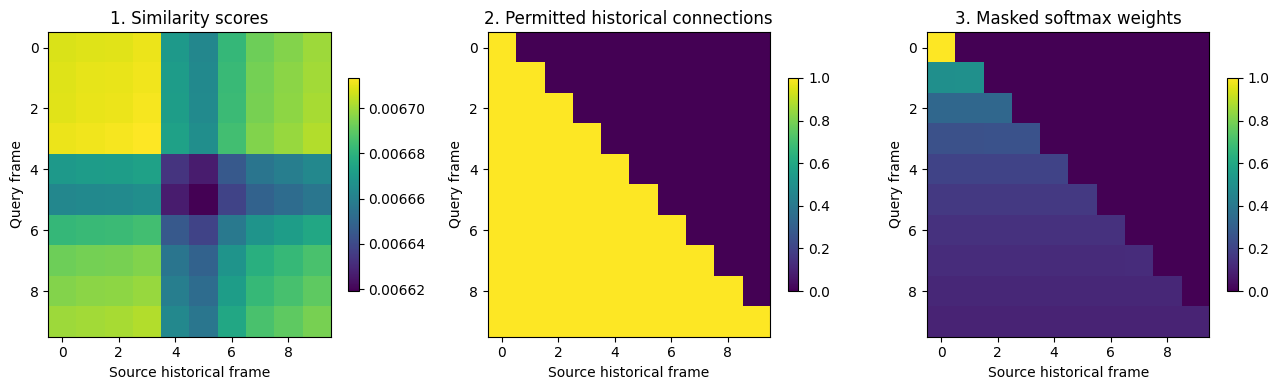

In [22]:
raw_scores,allowed,weights,weighted_history=causal_attention_steps(Z)
fig,axs=plt.subplots(1,3,figsize=(13,4))
for ax,data,title in zip(axs,[raw_scores,allowed,weights],['1. Similarity scores','2. Permitted historical connections','3. Masked softmax weights']):
    im=ax.imshow(data,aspect='auto');ax.set_title(title);ax.set(xlabel='Source historical frame',ylabel='Query frame');fig.colorbar(im,ax=ax,shrink=.7)
assert np.allclose(weights.sum(axis=1),1) and np.all(weights[~allowed]==0)
plt.tight_layout()
plt.show()

## Review the full method
Trace each final quantity back through its helper functions, intermediate arrays and visual diagnostics. Change one modeling assumption and rerun its dependent cells. Review coverage, attack direction, phase context and evaluation design before interpreting real sample results. Keep synthetic demonstrations and proxy quantities separate from trained or production model outputs.

This notebook is deliberately self-contained. Shared *concepts* such as smoothing or graph normalization are repeated inline where needed; another notebook never needs to run first.
